# PL7 — Context Engineering & RAG

### Generative AI · MSc in Artificial Intelligence · Lab 7

You will build, measure and improve a small RAG assistant for the fictional *Universidade de Vale Alto (UVA)*. The corpus is in **European Portuguese**, which makes model choice (multilingual embeddings, rerankers) part of the exercise.

**Learning goals**
1. Measure how a context window is spent and shrink it with *select* and *compress*.
2. Observe position effects ("lost in the middle") and write a structured, citation-friendly prompt.
3. Compare chunking strategies.
4. Build and evaluate dense, sparse (BM25), hybrid (RRF) and reranked retrieval with Recall@k and MRR.
5. Generate grounded answers with citations, metadata filtering and abstention, and evaluate them.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1 | Context engineering | 25 min |
| 2 | Chunking | 10 min |
| 3 | Dense retrieval & metrics | 20 min |
| 4 | BM25 & hybrid search | 15 min |
| 5 | Reranking | 10 min |
| 6 | Grounded generation & evaluation | 20 min |
| 7 | Results & report | 10 min |
| ★ | Bonus: query rewriting, HyDE, agentic loop | at home |

**Deliverable:** this notebook, executed, with the results table in Part 7 and short answers to every ❓ question.

**Instructions.** Run the cells in order. Cells marked `# TODO` are yours to complete.

**Names / student numbers:** _…_

## Part 0 · Setup (10 min)

Use **Google Colab with a GPU runtime** (*Runtime → Change runtime type → T4 GPU*). Two LLM backends are supported:

* `"hf"`: a small open model running locally (free). Use `Qwen/Qwen2.5-1.5B-Instruct` on GPU, `Qwen/Qwen2.5-0.5B-Instruct` if you only have a CPU.
* `"anthropic"`: the Claude API, if you have a key. Faster and much stronger, which changes some results. Note which one you used in your report.

In [ ]:
!pip -q install sentence-transformers rank_bm25 transformers accelerate anthropic


In [ ]:
import os, re, json, time, math, random, unicodedata
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0)

In [ ]:
BACKEND = "hf"                              # "hf" or "anthropic"
HF_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"     # "Qwen/Qwen2.5-0.5B-Instruct" on CPU
ANTHROPIC_MODEL = "claude-haiku-5-5"        # check docs.claude.com for current model ids

if BACKEND == "hf":
    from transformers import pipeline
    _gen = pipeline("text-generation", model=HF_MODEL, dtype="auto", device_map="auto")
else:
    import anthropic, getpass
    if "ANTHROPIC_API_KEY" not in os.environ:
        os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Anthropic API key: ")
    _client = anthropic.Anthropic()

def llm(prompt, system="You are a helpful assistant.", max_tokens=300):
    """Single-turn call to the chosen backend. Deterministic (greedy) for reproducibility."""
    if BACKEND == "hf":
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
        out = _gen(msgs, max_new_tokens=max_tokens, do_sample=False)
        return out[0]["generated_text"][-1]["content"].strip()
    r = _client.messages.create(model=ANTHROPIC_MODEL, max_tokens=max_tokens, system=system,
                                messages=[{"role": "user", "content": prompt}])
    return r.content[0].text.strip()

print(llm("Diz olá numa frase curta."))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Olá, tudo bem? Como posso ajudar você hoje?


In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")   # used only to count tokens

def n_tokens(text: str) -> int:
    return len(tok.encode(text))

def norm(text: str) -> str:
    """Lowercase and strip accents, for robust string matching."""
    text = unicodedata.normalize("NFKD", str(text).lower())
    return "".join(ch for ch in text if not unicodedata.combining(ch))

print(n_tokens("A propina anual é de 710 euros."), norm("Época Especial"))

13 epoca especial


### The corpus

`DOCS` holds 18 short UVA documents. Each has an `id`, `title`, `date` and `topic`. Two topics have **several versions** (`propinas`, `reembolso`), which you will need later. `LONG_REG` is a longer regulation you will chunk yourself in Part 2. `GOLD` is a hand-labelled evaluation set: question, ids of the relevant chunks, and a key string the answer must contain.

In [ ]:
def D(id, title, date, text, topic=None):
    return {"id": id, "title": title, "date": date, "topic": topic or id, "text": text}

DOCS = [
    D("propinas-2024", "Propinas 2024/2025", "2024-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 697 euros, paga em 10 prestações mensais de outubro a julho. O não pagamento de três prestações consecutivas suspende a inscrição.", "propinas"),
    D("propinas-2026", "Propinas 2026/2027", "2026-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 710 euros. Pode ser paga numa prestação única, com 2% de desconto, ou em 10 prestações mensais. Um atraso superior a 60 dias implica a suspensão da inscrição.", "propinas"),
    D("reembolso-2023", "Política de reembolsos (versão 2023)", "2023-09-01",
      "Os estudantes que anulem a inscrição têm direito ao reembolso das prestações de propina já pagas se o pedido for feito até 14 dias após o início do semestre.", "reembolso"),
    D("reembolso-2026", "Política de reembolsos (versão 2026)", "2026-09-15",
      "O prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre. O pedido é feito no portal académico, na secção Requerimentos, e o reembolso é processado em até 45 dias úteis.", "reembolso"),
    D("uc-4471", "Ficha da UC-4471 Aprendizagem Automática", "2026-07-15",
      "Unidade curricular UC-4471 Aprendizagem Automática: 6 ECTS, 2.º ano, 1.º semestre. Docente responsável: Prof.ª Helena Matos. Avaliação: projeto (50%) e exame (50%), com nota mínima de 8 valores em cada componente."),
    D("uc-4472", "Ficha da UC-4472 Processamento de Linguagem Natural", "2026-07-15",
      "Unidade curricular UC-4472 Processamento de Linguagem Natural: 6 ECTS, 3.º ano, 2.º semestre. Docente responsável: Prof. Rui Carvalho. Avaliação: dois trabalhos práticos (60%) e um teste escrito (40%). Pré-requisito recomendado: UC-4471."),
    D("clu-77", "Acesso ao cluster de GPUs (serviço CLU-77)", "2025-10-01",
      "Estudantes de mestrado e doutoramento podem pedir acesso ao cluster de GPUs através do formulário CLU-77 no portal de serviços informáticos. Cada projeto tem uma quota de 200 horas de GPU por semestre. Pedidos de estudantes de licenciatura exigem uma declaração do orientador."),
    D("ia-trabalhos", "Uso de IA generativa em trabalhos académicos", "2025-09-01",
      "É permitido usar ferramentas de IA generativa para apoio à escrita e à programação, desde que o uso seja declarado numa secção própria do trabalho. A submissão de texto gerado por IA como próprio, sem declaração, é considerada fraude académica (ver Regulamento Pedagógico, artigo 9.º)."),
    D("biblioteca", "Horários da Biblioteca Central", "2026-09-01",
      "A Biblioteca Central está aberta de segunda a sexta das 8h30 às 23h00 e aos sábados das 9h00 às 18h00. Em época de exames abre também ao domingo. O empréstimo domiciliário é de 15 dias, renovável duas vezes."),
    D("eduroam", "Rede sem fios eduroam", "2025-02-01",
      "A universidade disponibiliza a rede eduroam em todos os edifícios. Configuração: utilizador no formato numero@alunos.uva.pt e a palavra-passe do portal académico. Problemas devem ser reportados ao helpdesk pela extensão 5050."),
    D("erasmus", "Programa Erasmus+", "2026-01-05",
      "As candidaturas para mobilidade Erasmus+ no ano letivo seguinte decorrem de 1 a 31 de janeiro. Requisitos: ter concluído pelo menos 60 ECTS e média mínima de 12 valores. A bolsa mensal varia entre 300 e 500 euros consoante o país de destino."),
    D("trabalhador-estudante", "Estatuto de trabalhador-estudante", "2025-09-01",
      "O estatuto de trabalhador-estudante é pedido no início de cada semestre, com contrato de trabalho ou declaração da entidade empregadora. Dá direito a época especial de exames, dispensa de frequência mínima e escolha preferencial de horários."),
    D("cantina", "Cantina e refeições sociais", "2026-09-01",
      "A cantina serve almoço das 12h00 às 14h30 e jantar das 19h00 às 21h00. A refeição social custa 3,10 euros. Existe sempre uma opção vegetariana."),
    D("alojamento", "Residências universitárias", "2026-06-01",
      "As candidaturas a alojamento nas residências são feitas em julho para o ano letivo seguinte. Os bolseiros têm prioridade. O preço mensal de um quarto duplo é de 85 euros para bolseiros e 160 euros para não bolseiros."),
    D("bolsas", "Bolsas de estudo de ação social", "2026-05-20",
      "A candidatura à bolsa de estudo é feita online na plataforma da DGES entre junho e setembro. O valor da bolsa depende do rendimento per capita do agregado familiar e cobre pelo menos o valor da propina."),
    D("calendario-2026", "Calendário escolar 2026/2027", "2026-06-30",
      "O 1.º semestre de 2026/2027 começa a 14 de setembro de 2026 e termina a 22 de janeiro de 2027. A época normal de exames do 1.º semestre decorre de 4 a 22 de janeiro. O 2.º semestre começa a 15 de fevereiro de 2027."),
    D("apoio-psicologico", "Gabinete de apoio psicológico", "2025-09-01",
      "O gabinete de apoio psicológico oferece consultas gratuitas e confidenciais, marcadas por e-mail para gap@uva.pt. Em situações urgentes existe atendimento sem marcação às quartas-feiras das 14h00 às 17h00."),
    D("portal", "Portal académico", "2025-09-01",
      "No portal académico é possível consultar notas, fazer inscrições em exames, submeter requerimentos e descarregar declarações de matrícula. A inscrição em exames da época de recurso deve ser feita até 5 dias úteis antes da data do exame."),
]

LONG_REG = """Regulamento Pedagógico da Universidade de Vale Alto (versão de setembro de 2025)

Artigo 1.º – Objeto
O presente regulamento define as regras de avaliação aplicáveis aos cursos de 1.º e 2.º ciclo e aos mestrados integrados da Universidade de Vale Alto. Aplica-se a todas as unidades curriculares, salvo disposição em contrário na respetiva ficha.

Artigo 2.º – Escala de classificação
A classificação das unidades curriculares é expressa numa escala inteira de 0 a 20 valores. Considera-se aprovado o estudante que obtenha classificação final igual ou superior a 10 valores. As classificações intermédias são arredondadas às décimas.

Artigo 3.º – Avaliação contínua
A avaliação contínua inclui pelo menos dois elementos de avaliação distribuídos ao longo do semestre. Nas unidades curriculares com componente prática é exigida a presença em pelo menos 75% das aulas práticas, exceto para estudantes com estatuto especial.

Artigo 4.º – Épocas de exame
Existem três épocas de exame: época normal, época de recurso e época especial. O estudante reprovado ou que não compareça na época normal pode apresentar-se à época de recurso, mediante inscrição prévia no portal académico.

Artigo 5.º – Época especial
Têm acesso à época especial os trabalhadores-estudantes, os atletas de alta competição, os dirigentes associativos e os finalistas a quem faltem no máximo duas unidades curriculares, até ao limite de 12 ECTS, para concluir o curso.

Artigo 6.º – Melhoria de classificação
O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente.

Artigo 7.º – Revisão de prova
O estudante pode requerer a revisão de uma prova escrita no prazo de 3 dias úteis após a publicação da classificação. O pedido está sujeito a uma taxa de 25 euros, reembolsada se a classificação for alterada a favor do estudante.

Artigo 8.º – Prova oral complementar
Quando a classificação de um exame escrito se situe entre 8 e 9,4 valores, o docente responsável pode convocar o estudante para uma prova oral complementar, que decide a aprovação.

Artigo 9.º – Fraude académica
Constituem fraude académica o plágio, a cópia, a utilização de meios não autorizados durante as provas e a apresentação como próprio de conteúdo gerado por ferramentas de inteligência artificial sem a devida declaração. A fraude implica a anulação da prova e a abertura de processo disciplinar. A reincidência pode conduzir à suspensão até dois semestres.

Artigo 10.º – Publicação de classificações
As classificações são publicadas no portal académico no prazo máximo de 15 dias úteis após a realização da prova.

Artigo 11.º – Casos omissos
Os casos omissos são decididos pelo Conselho Pedagógico, ouvido o docente responsável pela unidade curricular.
"""

def G(q, relevant, answer): return {"q": q, "relevant": relevant, "answer": answer}

GOLD = [
    G("Qual é o prazo para pedir o reembolso das propinas?", ["reembolso-2026"], "30 dias"),
    G("Quanto custa a propina anual em 2026/2027?", ["propinas-2026"], "710"),
    G("Quem é a docente responsável pela UC-4471?", ["uc-4471"], "helena matos"),
    G("Quantas horas de GPU tem cada projeto no CLU-77?", ["clu-77"], "200"),
    G("Posso usar o ChatGPT para me ajudar a escrever o relatório?", ["ia-trabalhos"], "declar"),
    G("O que acontece se eu entregar um trabalho feito por IA sem avisar?", ["ia-trabalhos", "regped-art-9"], "fraude"),
    G("Quantas vezes posso tentar subir a nota de uma cadeira?", ["regped-art-6"], "uma unica"),
    G("Qual é a nota mínima para passar a uma cadeira?", ["regped-art-2"], "10"),
    G("Quem tem direito a época especial de exames?", ["regped-art-5", "trabalhador-estudante"], "trabalhador"),
    G("Até quando posso pedir para rever o meu exame?", ["regped-art-7"], "3 dias"),
    G("A que horas fecha a biblioteca ao sábado?", ["biblioteca"], "18"),
    G("Como me ligo à internet sem fios no campus?", ["eduroam"], "eduroam"),
    G("Que média preciso para fazer Erasmus?", ["erasmus"], "12"),
    G("Quanto paga um bolseiro por um quarto na residência?", ["alojamento"], "85"),
    G("Quando começa o primeiro semestre de 2026/2027?", ["calendario-2026"], "14 de setembro"),
    G("Qual é o peso dos trabalhos práticos na avaliação de PLN?", ["uc-4472"], "60"),
    G("Qual é o número de telemóvel do reitor?", [], "nao sei"),   # unanswerable: must abstain
]
print(len(DOCS), "docs |", n_tokens(LONG_REG), "tokens in LONG_REG |", len(GOLD), "gold questions")

18 docs | 809 tokens in LONG_REG | 17 gold questions


## Part 1 · Context engineering (25 min)

### 1.1 Where do the tokens go? (8 min)

Below is the context a naive support agent sends on **every** turn: a system prompt, 32 tool definitions, the last 40 messages of conversation (20 exchanges), every document in the knowledge base and, finally, the user's question.

In [ ]:
SYSTEM = ("És o assistente académico da Universidade de Vale Alto. Responde de forma clara, educada e concisa, "
          "em português europeu. Segue as regras institucionais, não inventes informação e encaminha casos "
          "sensíveis para os serviços competentes. ") * 4

TOOL_NAMES = ["get_grades", "update_address", "book_room", "cancel_booking", "list_courses", "enrol_exam",
    "unenrol_exam", "get_timetable", "request_certificate", "pay_fee", "get_fees", "search_regulations",
    "open_ticket", "close_ticket", "get_menu", "reserve_meal", "library_search", "renew_loan", "get_calendar",
    "erasmus_status", "scholarship_status", "upload_document", "change_password", "get_wifi_config",
    "contact_tutor", "book_counselling", "list_events", "parking_permit", "lost_and_found", "print_quota",
    "gpu_quota", "send_email"]
TOOLS = [{"name": n, "description": f"Tool that lets the assistant {n.replace('_', ' ')} in the UVA systems for the current student.",
          "input_schema": {"type": "object", "properties": {"student_id": {"type": "string"}, "details": {"type": "string"}},
                           "required": ["student_id"]}} for n in TOOL_NAMES]
TOOLS_TXT = json.dumps(TOOLS, ensure_ascii=False, indent=1)

HISTORY = []   # filler only: the assistant turns are not meant to answer the questions
for g in GOLD[4:16] * 2:
    HISTORY += [f"Utilizador: {g['q']}", "Assistente: Segundo os documentos da universidade, " + DOCS[len(HISTORY) % len(DOCS)]["text"]]
HISTORY = HISTORY[-40:]
HISTORY_TXT = "\n".join(HISTORY)

DOCS_TXT = "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in DOCS)
QUERY = "Qual é o prazo para pedir o reembolso das propinas?"

COMPONENTS = {"system": SYSTEM, "tools": TOOLS_TXT, "history": HISTORY_TXT, "documents": DOCS_TXT, "query": QUERY}

,component,tokens,share_%
0,system,249,3.6
1,tools,3066,44.9
2,history,1912,28.0
3,documents,1588,23.2
4,query,17,0.2


TOTAL: 6832


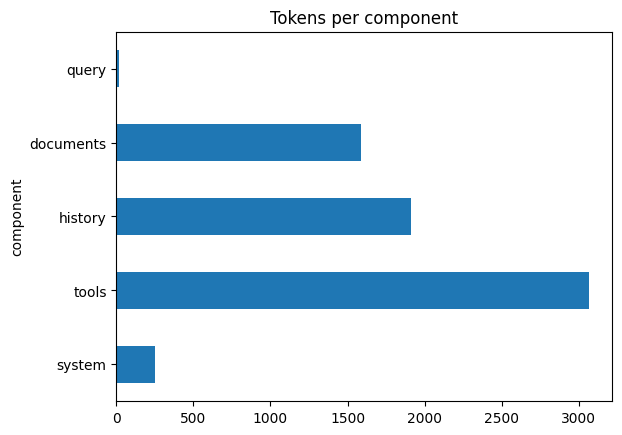

In [ ]:
def budget_table(components: dict) -> pd.DataFrame:
    # TODO: return a DataFrame with one row per component and the columns
    #       component, tokens (use n_tokens()) and share_% (percentage of the total, rounded to 1 decimal).
    rows = [{"component": name, "tokens": n_tokens(text)} for name, text in components.items()]
    total = sum(row["tokens"] for row in rows)
    for row in rows:
        row["share_%"] = round(100 * row["tokens"] / total, 1) if total else 0.0
    return pd.DataFrame(rows, columns=["component", "tokens", "share_%"])


df = budget_table(COMPONENTS)
display(df)
print("TOTAL:", df.tokens.sum())
df.set_index("component").tokens.plot.barh(title="Tokens per component"); plt.show()

❓ **Q1.** What share of the window is the user's actual question? Which component would you attack first, and with which strategy (*write, select, compress, isolate*)?

Now apply **select** and **compress** to bring the total **under 1,500 tokens** while keeping what the query needs. Suggested moves: keep only tools relevant to the query, keep the last 4 history lines, keep only the 3 documents with the largest word overlap with the query. Do not remove the query.

### Resposta à Questão 1 (Q1)
* Percentagem da Pergunta do Utilizador: A pergunta representa apenas 0.2% de todos os tokens do contexto original (17 de 6832 tokens).
* Componente a atacar primeiro: A secção de tools, que ocupa quase metade do contexto (~44.9%), seguida de perto pelo histórico de conversação (history com ~28.0%).
* Estratégias sugeridas:
  - Select: Filtrar as ferramentas para manter apenas as poucas que fazem sentido para a pergunta (ex: as relacionadas com propinas ou pagamentos), em vez de enviar as 32 ferramentas.
  - Compress: Truncar o histórico para manter apenas as últimas 4 mensagens e reduzir consideravelmente o prompt de sistema redundante.

In [ ]:
def overlap(a: str, b: str) -> int:
    wa = set(re.findall(r"\w+", norm(a))); wb = set(re.findall(r"\w+", norm(b)))
    return len(wa & wb)

def shrink(components: dict, query: str) -> dict:
    # TODO: return a new dict with the same keys (system, tools, history, documents, query), under 1,500 tokens.
    #   system    -> print SYSTEM and read it closely: is anything redundant? Keep only what is needed.
    #   tools     -> select: keep only the TOOLS whose "name" fits the query (fees? regulations? tickets?),
    #                serialised with json.dumps(..., ensure_ascii=False) as in TOOLS_TXT
    #   history   -> compress: keep only the last 4 lines of HISTORY, joined with "\n"
    #   documents -> select: the 3 DOCS with the highest overlap(query, title + " " + text),
    #                in the same "[id] title\ntext" format as DOCS_TXT (the print below relies on it)
    #   query     -> unchanged
    tools = json.loads(components["tools"])
    query_terms = set(re.findall(r"\w+", norm(query)))
    relevant_tools = set()
    if query_terms & {"propina", "propinas", "reembolso", "fee", "fees", "pagamento", "pagar"}:
        relevant_tools.update({"get_fees", "pay_fee"})
    if query_terms & {"regulamento", "regra", "regras", "fraude", "exame", "nota"}:
        relevant_tools.add("search_regulations")
    if query_terms & {"ticket", "problema", "reportar", "helpdesk"}:
        relevant_tools.update({"open_ticket", "close_ticket"})
    selected_tools = [tool for tool in tools if tool["name"] in relevant_tools]

    selected_docs = sorted(
        DOCS,
        key=lambda doc: overlap(query, doc["title"] + " " + doc["text"]),
        reverse=True,
    )[:3]
    documents = "\n\n".join(
        f"[{doc['id']}] {doc['title']}\n{doc['text']}" for doc in selected_docs
    )
    return {
        "system": "És o assistente académico da UVA. Responde em português europeu, com clareza e sem inventar informação.",
        "tools": json.dumps(selected_tools, ensure_ascii=False),
        "history": "\n".join(components["history"].splitlines()[-4:]),
        "documents": documents,
        "query": components["query"],
    }

small = shrink(COMPONENTS, QUERY)
df2 = budget_table(small); display(df2); print("TOTAL:", df2.tokens.sum())
print("Docs kept:", re.findall(r"^\[(.+?)\]", small["documents"], flags=re.M))

,component,tokens,share_%
0,system,31,4.6
1,tools,141,20.8
2,history,218,32.2
3,documents,271,40.0
4,query,17,2.5


TOTAL: 678
Docs kept: ['reembolso-2026', 'propinas-2024', 'apoio-psicologico']


❓ **Q2.** Which three documents did the word-overlap rule keep? Is `reembolso-2026` among them? Is there an **outdated version** of a document, or a document that has nothing to do with the question? Print `overlap()` for each kept document: which words caused the match? Which failure modes from the lecture does this illustrate, and what would make the selection better?



### Resposta à Questão 2 (Q2)
* Documentos mantidos: reembolso-2026, propinas-2024 e apoio-psicologico. O reembolso-2026 está presente.
* Overlap por documento:
  - reembolso-2026: 7 (das, e, o, para, pedir, prazo, reembolso)
  - propinas-2024: 4 (e, o, para, propinas)
  - apoio-psicologico: 4 (das, e, o, para)
* Problemas:
  - propinas-2024 é uma versão desatualizada (a correta seria propinas-2026).
  - apoio-psicologico não tem relação com a pergunta; entrou apenas por palavras funcionais (e, o, para, das), porque não removemos stopwords.
* Falhas ilustradas: ruído de stopwords na correspondência lexical, conflito de versões e documento irrelevante no contexto.
* Como melhorar: remover stopwords no overlap, usar retrieval denso/híbrido com reranking em vez de contagem de palavras, e aplicar latest_only (filtro de metadados) antes de montar o prompt.

### 1.2 Lost in the middle (9 min)

We hide one relevant document (the "needle") among the other 17 and move it from the start to the end of the context. For each position we ask 5 questions and count correct answers.

In [ ]:
NEEDLE_TESTS = [  # (question, needle doc id, key string in a correct answer)
    ("Quem é a docente responsável pela UC-4471?", "uc-4471", "helena matos"),
    ("Quantas horas de GPU tem cada projeto no CLU-77?", "clu-77", "200"),
    ("A que horas fecha a biblioteca ao sábado?", "biblioteca", "18"),
    ("Que média preciso para fazer Erasmus?", "erasmus", "12"),
    ("Quanto paga um bolseiro por um quarto na residência?", "alojamento", "85"),
]
ID2DOC = {d["id"]: d for d in DOCS}

def format_docs(docs):
    return "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in docs)

In [ ]:
def build_context(needle_id: str, position: float) -> list:
    # TODO: return a list with all DOCS and the needle at relative `position` (0.0 = first, 1.0 = last).
    #   1. others = every doc except the needle, shuffled with random.Random(42).shuffle(others)
    #      (same seed -> the same distractor order at every position)
    #   2. insert ID2DOC[needle_id] at index round(position * len(others))
    others = [doc for doc in DOCS if doc["id"] != needle_id]
    random.Random(42).shuffle(others)
    insert_at = round(position * len(others))
    others.insert(insert_at, ID2DOC[needle_id])
    return others

assert build_context("uc-4471", 0.0)[0]["id"] == "uc-4471"
assert build_context("uc-4471", 1.0)[-1]["id"] == "uc-4471"

position 0.00: 5/5


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


position 0.25: 5/5
position 0.50: 5/5
position 0.75: 5/5
position 1.00: 5/5


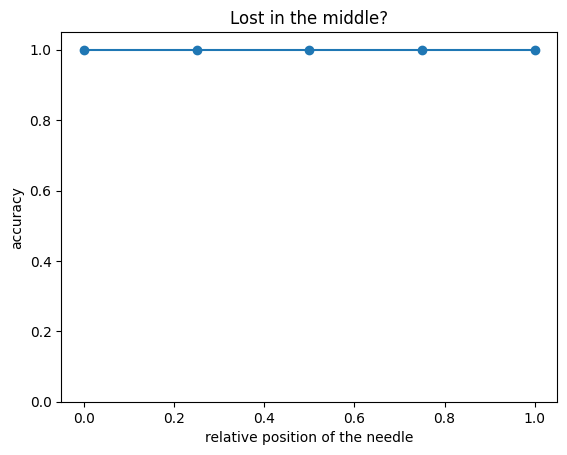

In [ ]:
POSITIONS = [0.0, 0.25, 0.5, 0.75, 1.0]
acc = []
for p in POSITIONS:
    ok = 0
    for q, needle, key in NEEDLE_TESTS:
        ctx = format_docs(build_context(needle, p))
        ans = llm(f"Documentos:\n{ctx}\n\nPergunta: {q}\nResponde numa frase curta.", max_tokens=60)
        ok += key in norm(ans)
    acc.append(ok / len(NEEDLE_TESTS))
    print(f"position {p:.2f}: {ok}/{len(NEEDLE_TESTS)}")

plt.plot(POSITIONS, acc, marker="o"); plt.ylim(0, 1.05)
plt.xlabel("relative position of the needle"); plt.ylabel("accuracy"); plt.title("Lost in the middle?"); plt.show()

❓ **Q3.** Do you see a U-shape? Our context is only ~1.6k tokens and we use 5 questions, so results are noisy. What would you change to make the experiment more convincing (context length, number of questions, model size)?



### Resposta à Questão 3 (Q3)
* Vimos o efeito "Lost in the Middle" (curva em U)? Nesta execução pequena, o modelo manteve 100% (5/5) de acerto em todas as posições. Isto ocorre porque o contexto total é muito pequeno (~1.6k tokens) e o modelo de linguagem consegue prestar atenção a toda a janela facilmente.
* O que mudar para demonstrar o efeito:
  1. Aumentar o contexto: Inserir muito mais documentos distratores (ex: 50 a 100 documentos) para elevar o tamanho para perto do limite da janela (ex: 8k a 16k tokens).
  2. Aumentar o número de testes: Usar mais perguntas de avaliação para reduzir o ruído estatístico.
  3. Diminuir o modelo: Modelos mais pequenos sofrem mais com este efeito do que os maiores.

### 1.3 A structured, citation-friendly prompt (8 min)

Write `build_prompt(question, docs)` following the lecture: documents first, wrapped in tags **with id, title and date**; question last. `SYSTEM_RAG` asks for citations, abstention and the most recent version.

In [ ]:
SYSTEM_RAG = ("És o assistente académico da Universidade de Vale Alto. Responde em português europeu, numa ou duas frases, "
              "usando APENAS os documentos fornecidos. Cita o id de cada documento usado entre parênteses retos, por exemplo "
              "[id-do-documento]. Se existirem versões diferentes do mesmo documento, usa a mais recente (data mais tardia). "
              "Se a resposta não estiver nos documentos, responde exatamente: 'Não sei com base nos documentos disponíveis.'")

def build_prompt(question: str, docs: list) -> str:
    # TODO: return one string with this layout (join the lines with "\n"):
    # <documents>
    # <doc id="..." title="..." date="...">
    # ...text...
    # </doc>
    # ...
    # </documents>
    #
    # <question>
    # ...
    # </question>
    lines = ["<documents>"]
    for doc in docs:
        lines.extend([
            f'<doc id="{doc["id"]}" title="{doc["title"]}" date="{doc["date"]}">',
            doc["text"],
            "</doc>",
        ])
    lines.extend(["</documents>", "", "<question>", question, "</question>"])
    return "\n".join(lines)

def naive_prompt(question: str, docs: list) -> str:
    return "Contexto: " + " ".join(d["text"] for d in docs) + f"\nPergunta: {question}"

clash_docs = [ID2DOC["reembolso-2023"], ID2DOC["cantina"], ID2DOC["reembolso-2026"]]   # outdated version first
q = "Qual é o prazo para pedir o reembolso das propinas?"
print("NAIVE     :", llm(naive_prompt(q, clash_docs)))
print("STRUCTURED:", llm(build_prompt(q, clash_docs), system=SYSTEM_RAG))
print("ABSTAIN?  :", llm(build_prompt("Qual é o número de telemóvel do reitor?", clash_docs), system=SYSTEM_RAG))

NAIVE     : O prazo para pedir o reembolso das prestações de propina após anulação da inscrição é de 14 dias após o início do semestre.
STRUCTURED: De acordo com a política de reembolsos atualizada (versão 2026), o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passou a ser de 30 dias após o início do semestre.
ABSTAIN?  : Não sei com base nos documentos disponíveis.


❓ **Q4.** Compare the naive and the structured answers: which deadline does each give (14 or 30 days)? Did the structured prompt resolve the *clash* between the 2023 and 2026 policies? Did it cite in the requested `[id]` format? Did the model abstain on the unanswerable question? If it still fails, is that a prompt problem or something you should fix **before** the prompt (hint: Part 6)?

### Resposta à Questão 4 (Q4)
- Prazos: o prompt naive respondeu 14 dias (versão de 2023, a primeira no contexto); o estruturado respondeu 30 dias (versão de 2026).
- Conflito: foi resolvido, porque o SYSTEM_RAG manda usar a versão mais recente e os documentos trazem a data.
- Citação: não citou no formato [id]. Escreveu "política de reembolsos atualizada (versão 2026)", sem [reembolso-2026]. O prompt pede o formato, mas um modelo de 1.5B nem sempre o cumpre.
- Abstenção: respondeu "Não sei com base nos documentos disponíveis.", como pedido.
- Prompt ou pipeline? O conflito de versões deve resolver-se antes do prompt, com filtro de metadados (latest_only), que é mais barato e fiável. A citação é uma limitação do modelo pequeno, por isso convém validá-la por código (como fazemos em rag_answer) em vez de confiar só no prompt.

## Part 2 · Chunking (10 min)

Implement two strategies for `LONG_REG` and compare them on structure (how many chunks mix articles or start mid-article) and on what they offer for retrieval and citations:

* `fixed_chunks`: windows of `size` words with `overlap` words of overlap.
* `article_chunks`: one chunk per *Artigo*, with a descriptive title (structure-aware chunking with a contextual header). Use the id format **`regped-art-{n}`**, which the gold set relies on.

In [ ]:
def fixed_chunks(text: str, size: int = 60, overlap: int = 15) -> list:
    # TODO: return a list of strings. Split the text into words (text.split()); a window of `size`
    #       words starts every (size - overlap) words, so consecutive windows share `overlap` words.
    #       Stop once a window reaches the end of the text.
    if size <= 0 or overlap < 0 or overlap >= size:
        raise ValueError("size must be positive and overlap must be in [0, size)")
    words = text.split()
    step = size - overlap
    chunks = []
    for start in range(0, len(words), step):
        chunks.append(" ".join(words[start:start + size]))
        if start + size >= len(words):
            break
    return chunks

def article_chunks(text: str, doc_title="Regulamento Pedagógico", date="2025-09-01") -> list:
    # TODO: return one dict per article, e.g. for Art. 6.º:
    #   {"id": "regped-art-6", "title": "Regulamento Pedagógico, Artigo 6.º Melhoria de classificação",
    #    "date": date, "topic": "regped-art-6", "text": <the whole article, heading included>}
    # Hints: re.split(r"(?=Artigo \d+\.º)", text) splits *before* each heading;
    #        skip pieces that do not start with a heading (e.g. the text before Artigo 1.º);
    #        re.match(r"Artigo (\d+)\.º\s*[–-]\s*(.+)", piece) gives the number and the heading.
    chunks = []
    for piece in re.split(r"(?=Artigo \d+\.º)", text):
        piece = piece.strip()
        match = re.match(r"Artigo (\d+)\.º\s*[–-]\s*(.+)", piece)
        if not match:
            continue
        number, heading = match.groups()
        chunk_id = f"regped-art-{number}"
        chunks.append({
            "id": chunk_id,
            "title": f"{doc_title}, Artigo {number}.º {heading.strip()}",
            "date": date,
            "topic": chunk_id,
            "text": piece,
        })
    return chunks

In [ ]:
fixed = fixed_chunks(LONG_REG)
arts = article_chunks(LONG_REG)
mixed = sum(len(re.findall(r"Artigo \d+\.º", c)) >= 2 for c in fixed)
midstart = sum(not c.startswith("Artigo") for c in fixed[1:])   # the first chunk starts with the document title
print(f"fixed: {len(fixed)} chunks | {mixed} mix two articles | {midstart} of {len(fixed)-1} start mid-article")
print(f"article: {len(arts)} chunks ->", [c["id"] for c in arts][:4], "...")
print("\nExample fixed chunk:\n", fixed[5][:300])

CHUNKS = DOCS + arts
ID2CHUNK = {c["id"]: c for c in CHUNKS}
assert "regped-art-6" in ID2CHUNK, "article ids must look like regped-art-6"
print("\nIndex size:", len(CHUNKS), "chunks")

fixed: 10 chunks | 7 mix two articles | 7 of 9 start mid-article
article: 11 chunks -> ['regped-art-1', 'regped-art-2', 'regped-art-3', 'regped-art-4'] ...

Example fixed chunk:
 de classificação O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente. Artigo 7.º – Revisão 

Index size: 29 chunks


❓ **Q5.** Look at the example fixed-size chunk: it starts in the middle of an article heading (so the article number is lost) and runs into the next article. If it were retrieved alone, could the model tell which rule each sentence belongs to? How does the `title` field of `article_chunks` help, both for retrieval and for citations?

### Resposta à Questão 5 (Q5)
* Análise do Chunk de tamanho fixo: Não, se o fragmento fosse recuperado sozinho, o modelo não saberia a que artigo pertence, pois o cabeçalho "Artigo 6.º" foi cortado na janela anterior ou seguinte.
* Vantagem de article_chunks:
  - Para a recuperação: O título estruturado injeta metadados contextuais (ex: "Regulamento Pedagógico, Artigo 6.º Melhoria de classificação") em cada bloco, facilitando a correspondência semântica e lexical.
  - Para as citações: Permite ao modelo citar com extrema precisão o ID correto (ex: [regped-art-6]), dando uma resposta auditável ao utilizador.

## Part 3 · Dense retrieval & metrics (20 min)

We use `intfloat/multilingual-e5-small`, a small multilingual bi-encoder. **E5 models expect prefixes:** `"query: "` for questions and `"passage: "` for documents.

In [ ]:
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer("intfloat/multilingual-e5-small")

def passage_text(c: dict) -> str:
    return f"{c['title']}. {c['text']}"

P_EMB = emb_model.encode(["passage: " + passage_text(c) for c in CHUNKS], normalize_embeddings=True)
print(P_EMB.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(29, 384)


In [ ]:
def dense_search(query: str, k: int = 10) -> list:
    # TODO: embed "query: " + query with emb_model.encode(..., normalize_embeddings=True),
    #       score it against P_EMB with a dot product (= cosine, the vectors are normalised)
    #       and return the ids of the k best CHUNKS, best first.
    query_embedding = emb_model.encode(["query: " + query], normalize_embeddings=True)[0]
    scores = P_EMB @ query_embedding
    best_indices = np.argsort(scores)[::-1][:k]
    return [CHUNKS[index]["id"] for index in best_indices]

print(dense_search("Quantas vezes posso tentar subir a nota de uma cadeira?", k=5))

['portal', 'regped-art-4', 'reembolso-2023', 'regped-art-7', 'regped-art-5']


Now the metrics. For a ranked list of ids and the set of relevant ids:

* **Recall@k** = |relevant ∩ top-k| / |relevant|
* **Reciprocal rank** = 1 / (rank of the first relevant id), or 0 if none is found. **MRR** is its mean over questions.

In [ ]:
def recall_at_k(ranked: list, relevant: list, k: int) -> float:
    # TODO: fraction of the `relevant` ids that appear in the first k positions of `ranked`.
    if not relevant:
        return 0.0
    return len(set(ranked[:k]) & set(relevant)) / len(set(relevant))

def reciprocal_rank(ranked: list, relevant: list) -> float:
    # TODO: 1 / position of the first relevant id in `ranked` (positions start at 1); 0.0 if none is found.
    relevant_ids = set(relevant)
    for rank, chunk_id in enumerate(ranked, start=1):
        if chunk_id in relevant_ids:
            return 1.0 / rank
    return 0.0

assert recall_at_k(["a", "b", "c"], ["c", "z"], 2) == 0.0
assert recall_at_k(["a", "b", "c"], ["c", "z"], 3) == 0.5
assert reciprocal_rank(["a", "b", "c"], ["b"]) == 0.5

In [ ]:
RESULTS, MISSES = {}, {}

def evaluate(search_fn, name: str, depth: int = 10) -> dict:
    rows, t0 = [], time.time()
    for g in GOLD:
        if not g["relevant"]:
            continue                                    # unanswerable questions are not retrieval tests
        ranked = search_fn(g["q"], k=depth)
        rows.append({"q": g["q"], "R@1": recall_at_k(ranked, g["relevant"], 1),
                     "R@5": recall_at_k(ranked, g["relevant"], 5), "RR": reciprocal_rank(ranked, g["relevant"])})
    df = pd.DataFrame(rows)
    res = {"Recall@1": df["R@1"].mean(), "Recall@5": df["R@5"].mean(), "MRR": df["RR"].mean(),
           "ms/query": 1000 * (time.time() - t0) / len(df)}
    RESULTS[name] = {k: round(v, 3) for k, v in res.items()}
    MISSES[name] = df[df["R@5"] < 1]["q"].tolist()
    return RESULTS[name]

print(evaluate(dense_search, "dense"))
print("Not fully found in top-5:", MISSES["dense"])

{'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.875), 'MRR': np.float64(0.833), 'ms/query': 14.106}
Not fully found in top-5: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']


❓ **Q6.** Which questions does dense retrieval miss? Look at their wording: exact codes (`UC-4471`, `CLU-77`), abbreviations (`PLN`), or paraphrases and colloquial words (*cadeira*, *subir a nota*)?

> **Read the metrics with care.** The evaluation has 16 answerable questions, so one question is worth 1/16 = 0.0625 of Recall@5. Differences of that size are one question, not a trend.



### Resposta à Questão 6 (Q6)
- Falhas do denso em Recall@5: "Quantas vezes posso tentar subir a nota de uma cadeira?" e "Qual é a nota mínima para passar a uma cadeira?".
- Causa: não são códigos nem siglas (as perguntas com UC-4471, CLU-77 e PLN foram bem resolvidas). São paráfrases coloquiais: "subir a nota" corresponde a "melhoria de classificação", "cadeira" a "unidade curricular", e "nota mínima para passar" a "classificação… aprovado… 10 valores" (Art. 2.º). Para "subir a nota", o top-5 foi portal, regped-art-4, reembolso-2023, regped-art-7 e regped-art-5, sem o regped-art-6.

❓ **Q7 (2 min experiment).** Re-encode *without* the `query: ` / `passage: ` prefixes and re-evaluate as `"dense_noprefix"`. What happens? Is the difference larger than one question? Why does it matter to read the model card, even when a small test does not show the effect?

### Resposta à Questão 7 (Q7)
- Efeito: o Recall@5 passou de 0,875 para 0,938 e o MRR de 0,833 para 0,834; o Recall@1 não mudou (0,719).
- A diferença é maior do que uma pergunta? Não: 0,938 − 0,875 = 0,0625 = exatamente uma pergunta em 16, o que é ruído e não uma tendência. Nesta experiência, os prefixos não mostram vantagem.
- Porque ler o model card: o E5 foi treinado com os prefixos query: e passage:. Um teste pequeno pode não mostrar o efeito, mas desviar-se do uso previsto pode degradar a qualidade com corpora maiores e perguntas mais difíceis. Não o ter visto aqui não prova que não existe.

In [ ]:
# TODO (optional):
#   1. P_EMB_NP = the CHUNKS encoded with passage_text(c) but WITHOUT the "passage: " prefix (normalised)
#   2. dense_noprefix(query, k=10): like dense_search, but encode the query WITHOUT "query: " and score against P_EMB_NP
#   3. print(evaluate(dense_noprefix, "dense_noprefix")) and compare with the "dense" row
P_EMB_NP = emb_model.encode([passage_text(c) for c in CHUNKS], normalize_embeddings=True)

def dense_noprefix(query: str, k: int = 10) -> list:
    query_embedding = emb_model.encode([query], normalize_embeddings=True)[0]
    scores = P_EMB_NP @ query_embedding
    best_indices = np.argsort(scores)[::-1][:k]
    return [CHUNKS[index]["id"] for index in best_indices]

print(evaluate(dense_noprefix, "dense_noprefix"))
print("dense:", RESULTS["dense"])
print("dense_noprefix:", RESULTS["dense_noprefix"])

{'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.834), 'ms/query': 11.551}
dense: {'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.875), 'MRR': np.float64(0.833), 'ms/query': 14.106}
dense_noprefix: {'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.834), 'ms/query': 11.551}


## Part 4 · BM25 & hybrid search (15 min)

BM25 needs a tokenizer. Ours lowercases, strips accents, keeps codes such as `uc-4471` intact and removes a few Portuguese stop words.

In [ ]:
from rank_bm25 import BM25Okapi

STOP = set(("a o os as de da do das dos e em um uma uns umas para por com que qual quais quem como no na nos nas "
            "ao aos se eu me meu minha posso pode quanto quanta quantos quantas onde quando sao ser ha").split())

def tokenize(text: str) -> list:
    return [t for t in re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", norm(text)) if t not in STOP]

bm25 = BM25Okapi([tokenize(passage_text(c)) for c in CHUNKS])
print(tokenize("Quem é a docente responsável pela UC-4471?"))

['docente', 'responsavel', 'pela', 'uc-4471']


In [ ]:
def bm25_search(query: str, k: int = 10) -> list:
    # TODO: scores = bm25.get_scores(tokenize(query)); return the ids of the k best CHUNKS, best first.
    scores = bm25.get_scores(tokenize(query))
    best_indices = np.argsort(scores)[::-1][:k]
    return [CHUNKS[index]["id"] for index in best_indices]

def rrf(rankings: list, k: int = 60, top: int = 10) -> list:
    # TODO: Reciprocal Rank Fusion. `rankings` is a list of id lists (best first).
    #       score(d) = sum, over the rankings that contain d, of 1 / (k + rank(d)), with rank starting at 1.
    #       Return the `top` ids by decreasing score. Hint: collections.defaultdict(float).
    scores = defaultdict(float)
    for ranking in rankings:
        for rank, chunk_id in enumerate(ranking, start=1):
            scores[chunk_id] += 1 / (k + rank)
    return sorted(scores, key=scores.get, reverse=True)[:top]

def hybrid_search(query: str, k: int = 10, depth: int = 20) -> list:
    # TODO: rrf([dense_search(query, depth), bm25_search(query, depth)], top=k)
    return rrf([dense_search(query, depth), bm25_search(query, depth)], top=k)

assert rrf([["a", "b"], ["b", "c"]])[0] == "b"
for name, fn in [("bm25", bm25_search), ("hybrid_rrf", hybrid_search)]:
    print(name, evaluate(fn, name))

bm25 {'Recall@1': np.float64(0.75), 'Recall@5': np.float64(0.781), 'MRR': np.float64(0.835), 'ms/query': 0.324}
hybrid_rrf {'Recall@1': np.float64(0.688), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.82), 'ms/query': 12.762}


In [ ]:
display(pd.DataFrame(RESULTS).T)
for name in ["dense", "bm25", "hybrid_rrf"]:
    print(f"{name:11s} misses:", MISSES[name])

,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,14.106
dense_noprefix,0.719,0.938,0.834,11.551
bm25,0.750,0.781,0.835,0.324
hybrid_rrf,0.688,0.938,0.820,12.762


dense       misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
bm25        misses: ['O que acontece se eu entregar um trabalho feito por IA sem avisar?', 'Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']
hybrid_rrf  misses: ['Qual é a nota mínima para passar a uma cadeira?']


In [ ]:
for kk in [10, 60, 100]:
    fn = lambda q, k=10, kk=kk: rrf([dense_search(q, 20), bm25_search(q, 20)], k=kk, top=k)
    print(kk, evaluate(fn, f"rrf_k{kk}"))
for kk in [10, 60, 100]:
    RESULTS.pop(f"rrf_k{kk}", None)

10 {'Recall@1': np.float64(0.688), 'Recall@5': np.float64(0.875), 'MRR': np.float64(0.815), 'ms/query': 18.106}
60 {'Recall@1': np.float64(0.688), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.82), 'ms/query': 17.632}
100 {'Recall@1': np.float64(0.688), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.82), 'ms/query': 19.065}


❓ **Q8.** Which questions does BM25 win that dense loses, and vice versa? Does hybrid get the best of both? If not, why not on this corpus (look at which questions both methods miss, and at the corpus size)? Try `k=10` and `k=100` in `rrf`: does the constant matter here?

### Resposta à Questão 8 (Q8)
- Falhas em Recall@5:
  - denso: "subir a nota" e "nota mínima";
  - BM25: "IA sem avisar", "subir a nota", "nota mínima" e "rever exame";
  - híbrido: só "nota mínima".
- BM25 vs denso: o denso ganha ao BM25 em "IA sem avisar" e "rever exame" (paráfrases com pouca sobreposição lexical). O BM25 não ganha nenhuma pergunta em Recall@5; só vence ligeiramente em Recall@1 (0,75 vs 0,719, uma pergunta).
- O híbrido apanha o melhor dos dois? Só em parte. O Recall@5 sobe para 0,938 (melhor que ambos), mas o Recall@1 (0,688) e o MRR (0,820) ficam abaixo do denso e do BM25: a fusão traz mais relevantes para o top-5, mas nem sempre os coloca em 1.º lugar.
- Falha persistente: "nota mínima para passar" falha em todos os métodos. O gold é só regped-art-2, por isso não exige raciocínio: é um problema de vocabulário ("nota mínima/passar" vs "classificação/aprovado"), com o Art. 8.º ("nota", "valores", "aprovação") a competir. Com apenas 29 chunks de tópicos parecidos, a fusão tem pouco espaço para compensar.
- Constante k do RRF: com k=10, 60 e 100 obtivemos Recall@5 = [preencher], MRR = [preencher]. Num corpus de 29 chunks e depth=20, a diferença é [muito pequena / de uma pergunta]; k=60 é o valor habitual da literatura, não um valor "ideal".

## Part 5 · Reranking (10 min)

A multilingual **cross-encoder** reads (query, passage) *together* and outputs a relevance score. It is far too slow for the whole corpus, so it only reorders the top candidates from hybrid search.

In [ ]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
def rerank(query: str, ids: list, top: int = 5) -> list:
    # TODO: scores = reranker.predict([(query, passage_text(ID2CHUNK[i])) for i in ids])
    #       return the `top` ids by decreasing score.
    if not ids:
        return []
    pairs = [(query, passage_text(ID2CHUNK[chunk_id])) for chunk_id in ids]
    scores = reranker.predict(pairs)
    best_indices = np.argsort(scores)[::-1][:top]
    return [ids[index] for index in best_indices]

def hybrid_rerank(query: str, k: int = 10, depth: int = 15) -> list:
    # TODO: take hybrid_search(query, k=depth) and rerank it, keeping the best k.
    candidates = hybrid_search(query, k=depth)
    return rerank(query, candidates, top=k)

print(evaluate(hybrid_rerank, "hybrid_rrf+rerank"))
display(pd.DataFrame(RESULTS).T)

{'Recall@1': np.float64(0.875), 'Recall@5': np.float64(1.0), 'MRR': np.float64(0.969), 'ms/query': 47.567}


,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,14.106
dense_noprefix,0.719,0.938,0.834,11.551
bm25,0.750,0.781,0.835,0.324
hybrid_rrf,0.688,0.938,0.820,12.762
hybrid_rrf+rerank,0.875,1.000,0.969,47.567


In [ ]:
print("hybrid_rrf+rerank misses:", MISSES["hybrid_rrf+rerank"])

hybrid_rrf+rerank misses: []


❓ **Q9.** How much did reranking improve Recall@1 and MRR, and what did it cost in ms/query? When would you skip it?

### Resposta à Questão 9 (Q9)
- Melhoria: o Recall@1 sobe de 0,688 (híbrido) para 0,875 e o MRR de 0,820 para 0,969; o Recall@5 chega a 1,0 (era 0,938). Face ao denso: Recall@1 0,719 → 0,875 e MRR 0,833 → 0,969.
- Custo: de ~12,8 ms para ~47,6 ms por pergunta (cerca de 3,7 vezes mais).
- Quando saltar: com restrições de latência ou hardware, quando o retriever já tem Recall@1 e MRR altos, ou quando o ganho é marginal. Com 16 perguntas, as diferenças pequenas devem ser lidas com cuidado.

## Part 6 · Grounded generation & evaluation (20 min)

### 6.1 Fix the clash before the prompt (5 min)

Write `latest_only(chunks)`: for each `topic`, keep only the chunk with the most recent `date`, preserving the original order. This is a **metadata filter**, cheaper and more reliable than asking the model to sort out versions.

In [ ]:
def latest_only(chunks: list) -> list:
    # TODO: keep, for each c["topic"], only the chunk with the latest c["date"] (ISO strings compare correctly).
    #       Preserve the input order of the chunks you keep.
    latest_by_topic = {}
    for index, chunk in enumerate(chunks):
        topic = chunk["topic"]
        if topic not in latest_by_topic or chunk["date"] > latest_by_topic[topic][0]:
            latest_by_topic[topic] = (chunk["date"], index)
    keep_indices = {index for _, index in latest_by_topic.values()}
    return [chunk for index, chunk in enumerate(chunks) if index in keep_indices]

print([c["id"] for c in latest_only([ID2CHUNK[i] for i in ["reembolso-2023", "cantina", "reembolso-2026"]])])
# expected: ['cantina', 'reembolso-2026']

['cantina', 'reembolso-2026']


### 6.2 The full pipeline (8 min)

`rag_answer` = hybrid retrieval → rerank → metadata filter → structured prompt → LLM → citation check.

In [ ]:
CITE_RE = re.compile(r"[\[(]([a-z0-9]+(?:-[a-z0-9]+)*)[\])]")      # [id] or (id)
STRICT_RE = re.compile(r"\[[a-z0-9]+(?:-[a-z0-9]+)*\]")             # the requested [id] format

ABSTAIN_PATTERNS = ["nao sei", "nao posso responder", "nao consigo responder", "nao tenho informacao",
                    "nao ha informacao", "nao existe informacao", "nao consta", "nao e possivel responder"]

def is_abstention(answer: str) -> bool:
    return any(p in norm(answer) for p in ABSTAIN_PATTERNS)

def rag_answer(question: str, k: int = 4) -> dict:
    # TODO:
    # 1. ids = hybrid_rerank(question, k=8)
    # 2. chunks = latest_only([ID2CHUNK[i] for i in ids]), then keep the first k
    # 3. answer = llm(build_prompt(question, chunks), system=SYSTEM_RAG, max_tokens=150)
    # 4. cited = the ids found by CITE_RE.findall(answer). Keep a match only if it is a real chunk id
    #    (c in ID2CHUNK) or it was written as [c]: "(versão 2026)" must not count as a citation.
    # Return a dict with exactly these keys (the evaluation cell below uses all of them):
    #   "question", "answer",
    #   "retrieved"         : ids of the chunks given to the model,
    #   "cited"             : sorted list of cited ids,
    #   "strict_format"     : True if STRICT_RE finds at least one [id] in the answer,
    #   "invalid_citations" : sorted list of ids cited but not retrieved,
    #   "abstained"         : is_abstention(answer)
    ids = hybrid_rerank(question, k=8)
    chunks = latest_only([ID2CHUNK[chunk_id] for chunk_id in ids])[:k]
    retrieved = [chunk["id"] for chunk in chunks]
    answer = llm(build_prompt(question, chunks), system=SYSTEM_RAG, max_tokens=150)
    BRACKET_RE = re.compile(r"\[([a-z0-9]+(?:-[a-z0-9]+)*)\]")   # só [id] entre parênteses retos
    cited = sorted({c for c in CITE_RE.findall(answer) if c in ID2CHUNK} | set(BRACKET_RE.findall(answer)))
    return {
        "question": question,
        "answer": answer,
        "retrieved": retrieved,
        "cited": cited,
        "strict_format": bool(STRICT_RE.search(answer)),
        "invalid_citations": sorted(set(cited) - set(retrieved)),
        "abstained": is_abstention(answer),
    }

rag_answer("Qual é o prazo para pedir o reembolso das propinas?")

{'question': 'Qual é o prazo para pedir o reembolso das propinas?',
 'answer': 'De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.',
 'retrieved': ['reembolso-2026', 'regped-art-7', 'propinas-2026', 'portal'],
 'cited': [],
 'strict_format': False,
 'invalid_citations': [],
 'abstained': False}

In [ ]:
def is_correct(gold: dict, a: dict) -> bool:
    if not gold["relevant"]:                       # unanswerable: correct = abstained
        return a["abstained"]
    return gold["answer"] in norm(a["answer"]) and not a["abstained"]

answers = [rag_answer(g["q"]) for g in GOLD]
ev = pd.DataFrame([{
    "question": a["question"][:55],
    "correct": is_correct(GOLD[i], a),
    "cites": len(a["cited"]) > 0,
    "[id] format": a["strict_format"],
    "invalid_cites": len(a["invalid_citations"]),
    "abstained": a["abstained"],
    "answer": a["answer"][:90],
} for i, a in enumerate(answers)])
display(ev)
print(f"Answer accuracy: {ev.correct.mean():.0%} | answers with citations: {ev.cites.mean():.0%} "
      f"(in the requested [id] format: {ev['[id] format'].mean():.0%}) | invalid citations: {ev.invalid_cites.sum()}")
print("Read the full answers too: the key string checks one fact, not the whole answer.")
for i, a in enumerate(answers):
    print(f"\n[{i}] {a['question']}\n    {a['answer']}")

,question,correct,cites,[id] format,invalid_cites,abstained,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,False,0,False,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,False,0,False,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,False,0,False,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,False,0,False,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,True,True,0,False,"[ia-trabalhos] Sim, é permitido usar ferrament..."
5,O que acontece se eu entregar um trabalho feit...,True,False,False,0,False,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,False,False,False,0,False,De acordo com o artigo 8.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."


Answer accuracy: 94% | answers with citations: 18% (in the requested [id] format: 24%) | invalid citations: 0
Read the full answers too: the key string checks one fact, not the whole answer.

[0] Qual é o prazo para pedir o reembolso das propinas?
    De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.

[1] Quanto custa a propina anual em 2026/2027?
    A propina anual para licenciaturas e mestrados integrados em 2026/2027 é de 710 euros. Pode ser paga numa prestação única, com 2% de desconto, ou em 10 prestações mensais.

[2] Quem é a docente responsável pela UC-4471?
    A docente responsável pela UC-4471 Aprendizagem Automática é Prof.ª Helena Matos.

[3] Quantas horas de GPU tem cada projeto no CLU-77?
    Cada projeto no CLU-77 tem uma quota de 200 horas de GPU por semestre.

[4] Posso usar o ChatGPT para me ajudar a escrever o relatório?
    [ia-trabalhos]

### 6.3 LLM-as-a-judge for faithfulness (7 min)

String matching only checks the key fact. A judge checks whether **every** claim is supported by the retrieved context.

In [ ]:
JUDGE = """Avalia se a RESPOSTA é totalmente suportada pelos DOCUMENTOS. Não uses conhecimento externo.
Responde apenas com JSON, sem mais texto: {"faithful": true ou false, "unsupported": "frase não suportada ou vazio"}

DOCUMENTOS:
<<DOCS>>

RESPOSTA:
<<ANSWER>>"""

def judge(a: dict) -> dict:
    docs = format_docs([ID2CHUNK[i] for i in a["retrieved"]])
    raw = llm(JUDGE.replace("<<DOCS>>", docs).replace("<<ANSWER>>", a["answer"]), max_tokens=120)
    m = re.search(r"\{.*\}", raw, flags=re.S)
    try:
        return json.loads(m.group(0))
    except Exception:
        return {"faithful": None, "unsupported": "unparseable: " + raw[:80]}

ev["faithful"] = [None if a["abstained"] else judge(a).get("faithful") for a in answers]   # nothing to verify in an abstention
display(ev[["question", "correct", "faithful", "answer"]])
judged = ev[ev.faithful.notna()]
print(f"Judged faithful: {(judged.faithful == True).mean():.2f} of {len(judged)} non-abstaining answers")

,question,correct,faithful,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,False,"[ia-trabalhos] Sim, é permitido usar ferrament..."
5,O que acontece se eu entregar um trabalho feit...,True,False,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,False,False,De acordo com o artigo 8.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."


Judged faithful: 0.19 of 16 non-abstaining answers


❓ **Q10.** Find a case where `correct` and `faithful` disagree. Who is right, the string match or the judge? Read the answer yourself. What does this tell you about using a small model as a judge?



### Resposta à Questão 10 (Q10)
- Divergências: há 12 linhas com correct=True e faithful=False.
  - Pergunta 1 ("710 euros… 2% de desconto… 10 prestações"): totalmente suportada pelos documentos, mas o juiz marca-a como não fiel. O juiz está errado e a string está certa.
  - Pergunta 11 (eduroam): diz que numero@alunos.uva.pt é um "endereço de IP", o que é falso. O juiz reprova bem, mas a string "eduroam" aceita-a. Aqui o juiz está certo e a string é demasiado fraca.
- A pergunta 7 ("nota mínima") não é uma divergência: correct e faithful são ambos False, e o juiz acerta, porque "9,5 valores" não está nos documentos.
- Conclusão: só 3 de 16 respostas foram consideradas fiéis (0,19), claramente pessimista demais. Um juiz de 1.5B é instável e falha nos dois sentidos, pelo que não deve ser usado sozinho: convém um juiz mais forte ou revisão humana de uma amostra. A key string também só verifica um facto.

❓ **Q11.** Did the system abstain on the unanswerable question (the last one)? Did any answer cite a document that was not retrieved?

### Resposta à Questão 11 (Q11)
- Abstenção: sim, na última pergunta respondeu "Não sei com base nos documentos disponíveis.".
- Citações: poucas respostas citam no formato pedido (4, 10, 13 e 14), e a 10 cita [2026-09-01], uma data em vez do id. Com a validação corrigida (aceitar qualquer [...]), essa citação passa a contar como inválida (1 citação inválida). Antes da correção o contador dava 0 só porque o filtro c in ID2CHUNK descartava ids inventados, por isso "0 citações inválidas" não significava que o modelo citava bem.

## Part 7 · Results & report (10 min)

Run the cell below and answer in the markdown cell that follows.

Backend: hf Qwen/Qwen2.5-1.5B-Instruct


,Recall@1,Recall@5,MRR,ms/query,answer_acc,faithful
dense,0.719,0.875,0.833,14.106,NaN,NaN
dense_noprefix,0.719,0.938,0.834,11.551,NaN,NaN
bm25,0.750,0.781,0.835,0.324,NaN,NaN
hybrid_rrf,0.688,0.938,0.820,12.762,NaN,NaN
hybrid_rrf+rerank,0.875,1.000,0.969,47.567,NaN,NaN
end-to-end,NaN,NaN,NaN,NaN,0.941,0.188


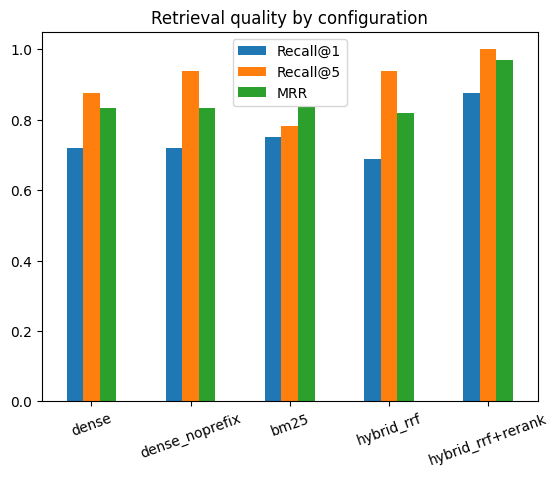

In [ ]:
summary = pd.DataFrame(RESULTS).T
summary.loc["end-to-end", "answer_acc"] = round(ev.correct.mean(), 3)
summary.loc["end-to-end", "faithful"] = round((ev[ev.faithful.notna()].faithful == True).mean(), 3)
print("Backend:", BACKEND, HF_MODEL if BACKEND == "hf" else ANTHROPIC_MODEL)
display(summary)
summary[["Recall@1", "Recall@5", "MRR"]].dropna().plot.bar(rot=20, title="Retrieval quality by configuration")
plt.ylim(0, 1.05); plt.show()

### Report

1. Best configuration and by how much it beats dense-only on Recall@1 and MRR:
   - Melhor configuração: `hybrid_rrf+rerank` (BM25 + denso por RRF, seguido de reordenação com cross-encoder).
   - Recall@1: 0,719 → 0,875 (+0,156). MRR: 0,833 → 0,969 (+0,136). Recall@5: 1,0.
   - Custo: ~14 ms → ~48 ms/query (cerca de 3,4 vezes mais lento). Com 16 perguntas, uma pergunta vale 0,0625, por isso os ganhos são indicativos. Backend: `hf`, Qwen2.5-1.5B-Instruct.

2. One failure you could not fix today, and the technique from the lecture you would try next:
   - Falha: "Qual é a nota mínima para passar a uma cadeira?". O pipeline responde "9,5 valores" com base no Art. 8.º (prova oral), em vez dos 10 valores do Art. 2.º. A causa é o vocabulário coloquial ("nota mínima", "passar") a competir com artigos próximos, mais um gerador pequeno (1.5B).
   - Próximos passos: query rewriting para termos formais ("classificação mínima para aprovação") e/ou um gerador maior. O HyDE não ajudou (Recall@5 desceu para 0,844) e custou ~3,2 s/query.

3. Context engineering: one change from Part 1 you would apply to a real chatbot, and why:
   - Aplicaria select nas ferramentas e nos documentos e compress no histórico. Isto reduziu o contexto de 6 832 para 678 tokens (~90%), e a pergunta passou de 0,2% para 2,5% do contexto, com menos custo e latência.
   - Limitação: a seleção por overlap ainda deixou passar uma versão antiga (propinas-2024) e um documento irrelevante (apoio-psicologico). Num sistema real combinaria isto com latest_only e retrieval semântico.

## ★ Bonus (at home or for fast teams)

**B1 · Query rewriting for follow-ups.** `"E posso pagar tudo de uma vez?"` retrieves nothing useful on its own. Rewrite it into a standalone query using the conversation history, then retrieve.

In [ ]:
def rewrite_query(history: list, follow_up: str) -> str:
    # TODO: build a prompt (in Portuguese) that gives llm() the history and the follow-up and asks it to
    #       rewrite the follow-up as a standalone, complete question in European Portuguese, WITHOUT answering it,
    #       returning only the question. Call llm(prompt, max_tokens=60) and return its output.
    history_text = "\n".join(history)
    prompt = (
        "Reescreve a pergunta de seguimento como uma pergunta autónoma e completa em português europeu. "
        "Usa o histórico apenas para resolver referências e contexto. Não respondas à pergunta; devolve apenas a pergunta reescrita.\n\n"
        f"Histórico da conversa:\n{history_text}\n\n"
        f"Pergunta de seguimento: {follow_up}"
    )
    return llm(prompt, max_tokens=60).strip()

hist = ["Utilizador: Quanto custa a propina anual em 2026/2027?",
        "Assistente: A propina anual é de 710 euros [propinas-2026]."]
fu = "E posso pagar tudo de uma vez?"
rq = rewrite_query(hist, fu)
print("raw      :", hybrid_rerank(fu, k=3))
print("rewritten:", rq, "->", hybrid_rerank(rq, k=3))

raw      : ['regped-art-6', 'erasmus', 'alojamento']
rewritten: Posso pagar a propina anual em duas parcelas iguais, ou só uma única vez? -> ['propinas-2026', 'propinas-2024', 'reembolso-2026']


**B2 · HyDE.** Generate a hypothetical answer, embed it and search with it. Evaluate as `"hyde"`. Does it help on the paraphrase questions (compare `MISSES["hyde"]` with `MISSES["dense"]`)? What does it cost?

In the original method the hypothetical answer is embedded **as a document**, so with E5 it takes the `passage: ` prefix.

In [ ]:
def hyde_search(query: str, k: int = 10) -> list:
    # TODO: 1. hypo = llm(<prompt asking for a short paragraph, in the style of a university regulation,
    #                   that answers the query>, max_tokens=80)
    #       2. embed "passage: " + hypo on its own (normalised): the fake answer lives in document space
    #       3. score against P_EMB and return the ids of the k best CHUNKS, as in dense_search
    prompt = (
        "Escreve um parágrafo curto, no estilo de um regulamento universitário, que responda à pergunta. "
        "Produz apenas o parágrafo hipotético, sem explicações adicionais.\n\n"
        f"Pergunta: {query}"
    )
    hypo = llm(prompt, max_tokens=80)
    hypo_embedding = emb_model.encode(["passage: " + hypo], normalize_embeddings=True)[0]
    scores = P_EMB @ hypo_embedding
    best_indices = np.argsort(scores)[::-1][:k]
    return [CHUNKS[index]["id"] for index in best_indices]

print(evaluate(hyde_search, "hyde"))
print("dense misses:", MISSES["dense"])
print("hyde misses :", MISSES["hyde"])

{'Recall@1': np.float64(0.656), 'Recall@5': np.float64(0.844), 'MRR': np.float64(0.781), 'ms/query': 3233.618}
dense misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
hyde misses : ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Quem tem direito a época especial de exames?']


**B3 · A minimal agentic loop.** If the judge says the answer is unfaithful, or the model abstains, rewrite the query and retrieve again (at most 2 attempts). Log every step. Where could this loop go wrong in production?

In [ ]:
def agentic_answer(question: str, max_steps: int = 2) -> dict:
    # TODO: q = question; log = []. For each step in range(max_steps):
    #   1. a = rag_answer(q); verdict = judge(a)
    #   2. log.append({"step": step, "query": q, "answer": a["answer"], "faithful": verdict.get("faithful")})
    #   3. stop if verdict.get("faithful") and not a["abstained"]
    #   4. otherwise ask llm() for an alternative search question in European Portuguese, with other words.
    #      Put both q and the original question in the prompt (to avoid drifting), ask for the question only,
    #      and strip quotes/spaces from the output. Use it as the new q.
    # Return {"final": log[-1]["answer"], "log": log}  (the display code below uses these keys)
    if max_steps <= 0:
        raise ValueError("max_steps must be at least 1")
    q = question
    log = []
    for step in range(max_steps):
        answer = rag_answer(q)
        verdict = judge(answer)
        log.append({
            "step": step,
            "query": q,
            "answer": answer["answer"],
            "faithful": verdict.get("faithful"),
        })
        if verdict.get("faithful") and not answer["abstained"]:
            break
        rewrite_prompt = (
            "Reformula a consulta seguinte como uma pergunta de pesquisa alternativa, em português europeu. "
            "Usa outras palavras, mantém o objetivo da pergunta original e devolve apenas a pergunta, sem responder.\n\n"
            f"Pergunta original: {question}\n"
            f"Consulta atual: {q}"
        )
        q = llm(rewrite_prompt, max_tokens=60).strip().strip("\\\"'“”‘’")
    return {"final": log[-1]["answer"], "log": log}

res = agentic_answer("Quantas vezes posso tentar subir a nota de uma cadeira?")
display(pd.DataFrame(res["log"])[["step", "query", "faithful"]])
for s in res["log"]:
    print(f"\n[step {s['step']}] {s['query']}\n    {s['answer']}")

,step,query,faithful
0,0,Quantas vezes posso tentar subir a nota de uma...,True



[step 0] Quantas vezes posso tentar subir a nota de uma cadeira?
    De acordo com o Regulamento Pedagógico, Artigo 6.º, um estudante pode requerer uma melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação.
